# Previsão de Óbito por SRAG — Projeto de Ciência de Dados e IA

**Disciplina:** Ciência de Dados e Inteligência Artificial  
**Grupo:** 3WA-01

| Nome | Matrícula |
|------|-----------|
| Leo Land Bairos Lomardo | 2020201 |
| Guilherme Meira Diniz | 2412246 |
| Pedro Mesquita Maia | 2312664 |
| João Miguel da Costa Araújo | 2410828 |

---

## Contexto e Objetivo

A Síndrome Respiratória Aguda Grave (SRAG) é uma condição de saúde pública monitorada pelo Ministério da Saúde do Brasil. O banco de dados SRAG reúne notificações hospitalares de pacientes com diagnóstico de SRAG de todo o país.

**Objetivo principal:** Desenvolver um modelo de classificação para prever o risco de óbito hospitalar por SRAG com base em variáveis clínicas e demográficas disponíveis no momento da internação.

**Por que isso importa:** Identificar pacientes com maior risco de óbito permite priorização de recursos clínicos e intervenção precoce.

**Fonte dos dados:** [Portal de Dados Abertos do Ministério da Saúde](https://dadosabertos.saude.gov.br/dataset/srag-2019-a-2026)  
**Dicionário de variáveis:** [Link](https://dadosabertos.saude.gov.br/dataset/srag-2019-a-2026/resource/3135ac9c-2019-4989-a893-2ed50ebd8e68)


## Plano de Execução

| Etapa | Descrição | Status |
|-------|-----------|--------|
| 1 | Instalação e importação de bibliotecas | ✅ |
| 2 | Carregamento do dataset SRAG 2025 | ✅ |
| 3 | Análise exploratória dos dados (EDA) | ✅ |
| 4 | Remoção de outliers | ✅ |
| 5 | Pré-processamento (variável alvo, extração de texto, limpeza de colunas) | ✅ |
| 6 | Seleção de features e correção de tipos | ✅ |
| 7 | Análise do desbalanceamento de classes | ✅ |
| 8 | Treinamento de modelos baseline (Árvore, Regressão Logística, LightGBM) | ✅ |
| 9 | Técnicas de balanceamento (RUS, SMOTE, SMOTEENN) + XGBoost | ✅ |
| 10 | Modelo final com pipeline corrigido (split 70/15/15) | ✅ |
| 11 | Avaliação final, visualizações e análise de importância | ✅ |
| 12 | Análise de complexidade computacional | ✅ |
| 13 | Discussão, conclusões e melhorias futuras | ✅ |


## 1. Instalação de Bibliotecas

Bibliotecas não padrão utilizadas no projeto:

In [1]:
!pip install gdown lightgbm xgboost imbalanced-learn -q
print("Instalação concluída.")


Instalação concluída.


## 2. Importação de Bibliotecas

In [2]:
import re
import io
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, average_precision_score,
    precision_recall_curve, f1_score,
    recall_score, precision_score,
    RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTEENN

plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 40)
print("Bibliotecas carregadas com sucesso.")


Bibliotecas carregadas com sucesso.


## 3. Carregamento dos Dados

O dataset SRAG 2025 está disponível publicamente via portal do Ministério da Saúde.  
**Nota:** A URL abaixo contém a data da última atualização do arquivo. Caso não funcione, verifique a URL mais recente em:  
https://dadosabertos.saude.gov.br/dataset/srag-2019-a-2026

Alternativa: use o gdown com o arquivo no Google Drive (comentado abaixo).


In [3]:
# OPÇÃO 1: Download direto do portal de dados abertos (recomendado)
URL_SRAG_2025 = (
    "https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br/"
    "SRAG/2025/INFLUD25-15-06-2026.csv"
)

print("Baixando dataset SRAG 2025 (~381 MB, aguarde)...")
response = requests.get(URL_SRAG_2025)
response.raise_for_status()
srag_df = pd.read_csv(
    io.BytesIO(response.content), sep=';', encoding='latin-1', low_memory=False
)

# OPÇÃO 2: Caso a OPÇÃO 1 falhe (ex.: URL desatualizada), use o Google Drive
# import gdown
# gdown.download("https://drive.google.com/uc?id=1rEsVhrcD09pneFiAaCBdGHQPzYXKdblg",
#                "srag_2025.csv", quiet=False)
# srag_df = pd.read_csv("srag_2025.csv", sep=';', encoding='latin-1', low_memory=False)

print(f"Dataset carregado: {srag_df.shape[0]:,} registros | {srag_df.shape[1]} colunas")


Baixando dataset SRAG 2025 (~381 MB, aguarde)...
Dataset carregado: 336,243 registros | 194 colunas


## 4. Análise Exploratória dos Dados (EDA)

### 4.1 Visão Geral

In [4]:
print(f"Linhas: {srag_df.shape[0]:,}  |  Colunas: {srag_df.shape[1]}")

nulos = srag_df.isnull().sum().sort_values(ascending=False)
resumo_nulos = pd.DataFrame({
    'coluna': nulos.index,
    'qtd_nulos': nulos.values,
    'percentual_nulos (%)': (nulos.values / len(srag_df) * 100).round(2)
})

print("\nTop 10 colunas com mais valores ausentes:")
display(resumo_nulos.head(10))
print("\nTop 10 colunas mais preenchidas:")
display(resumo_nulos.sort_values('qtd_nulos').head(10))


Linhas: 336,243  |  Colunas: 194

Top 10 colunas com mais valores ausentes:


,coluna,qtd_nulos,percentual_nulos (%)
0,TABAG,336243,100.00
1,DT_RT_VGM,336243,100.00
2,PAIS_VGM,336243,100.00
3,LO_PS_VGM,336243,100.00
4,VG_REINF,336243,100.00
5,DT_VGM,336243,100.00
6,CO_PS_VGM,336243,100.00
7,FLUBLI_OUT,336233,100.00
8,AN_PARA2,336231,100.00
9,AN_PARA3,336226,99.99



Top 10 colunas mais preenchidas:


,coluna,qtd_nulos,percentual_nulos (%)
188,HISTO_VGM,0,0.0
189,DT_DIGITA,0,0.0
190,POV_CT,0,0.0
191,TEM_CPF,0,0.0
187,NU_IDADE_N,0,0.0
186,CS_SEXO,0,0.0
185,CO_MUN_NOT,0,0.0
184,ID_MUNICIP,0,0.0
183,CS_GESTANT,0,0.0
182,CS_RACA,0,0.0


### 4.2 Metadados e Tipos de Dados

In [5]:
metadados_df = pd.DataFrame({
    'coluna': srag_df.columns,
    'tipo_dado': srag_df.dtypes.astype(str).values,
    'qtd_nao_nulos': srag_df.notnull().sum().values,
    'qtd_nulos': srag_df.isnull().sum().values,
    'qtd_valores_unicos': srag_df.nunique(dropna=True).values
})
metadados_df['fill_rate (%)'] = (metadados_df['qtd_nao_nulos'] / len(srag_df) * 100).round(2)

print("Resumo por tipo de dado:")
display(metadados_df['tipo_dado'].value_counts().reset_index())

colunas_quase_vazias = srag_df.isnull().mean()
colunas_quase_vazias = colunas_quase_vazias[colunas_quase_vazias >= 0.9999]
print(f"\nColunas totalmente nulas (≥99.99% missing): {len(colunas_quase_vazias)}")
print(colunas_quase_vazias.index.tolist())


Resumo por tipo de dado:


,tipo_dado,count
0,float64,103
1,object,77
2,int64,14



Colunas totalmente nulas (≥99.99% missing): 11
['TABAG', 'FLUBLI_OUT', 'PAIS_VGM', 'CO_PS_VGM', 'LO_PS_VGM', 'DT_VGM', 'DT_RT_VGM', 'AN_PARA1', 'AN_PARA2', 'AN_PARA3', 'VG_REINF']


### 4.3 Distribuição de Variáveis Categóricas Importantes

In [6]:
# Dicionário das principais variáveis categóricas:
# CLASSI_FIN: 1=SRAG Influenza, 2=Outro vírus, 3=Outro agente, 4=Não especificado, 5=Covid-19
# EVOLUCAO:   1=Cura, 2=Óbito, 3=Óbito por outra causa, 9=Ignorado
# CS_SEXO:    M=Masculino, F=Feminino, I=Ignorado

colunas_cat = ['CS_SEXO', 'SG_UF_NOT', 'CLASSI_FIN', 'EVOLUCAO']

for col in colunas_cat:
    freq = pd.DataFrame({
        'valor': srag_df[col].value_counts(dropna=False).index,
        'quantidade': srag_df[col].value_counts(dropna=False).values,
        'percentual (%)': (srag_df[col].value_counts(dropna=False, normalize=True).values * 100).round(2)
    })
    print(f"\n=== {col} ===")
    display(freq.head(8))



=== CS_SEXO ===


,valor,quantidade,percentual (%)
0,M,173483,51.59
1,F,162720,48.39
2,I,40,0.01



=== SG_UF_NOT ===


,valor,quantidade,percentual (%)
0,SP,79355,23.60
1,MG,45490,13.53
2,PR,32030,9.53
3,RJ,23319,6.94
4,RS,20497,6.10
5,SC,18239,5.42
6,BA,14220,4.23
7,DF,13140,3.91



=== CLASSI_FIN ===


,valor,quantidade,percentual (%)
0,4.0,154346,45.90
1,2.0,104088,30.96
2,1.0,46528,13.84
3,5.0,17938,5.33
4,NaN,9216,2.74
5,3.0,4127,1.23



=== EVOLUCAO ===


,valor,quantidade,percentual (%)
0,1.0,281794,83.81
1,2.0,22935,6.82
2,NaN,16243,4.83
3,3.0,9060,2.69
4,9.0,6211,1.85


### 4.4 Fill Rate e Padrão de Valores Ausentes

Top 20 colunas mais preenchidas:


,coluna,fill_rate (%)
0,NU_NOTIFIC,100.0
1,DT_NOTIFIC,100.0
2,SEM_NOT,100.0
3,DT_SIN_PRI,100.0
4,SEM_PRI,100.0
5,SG_UF_NOT,100.0
9,CO_MUN_NOT,100.0
8,ID_MUNICIP,100.0
12,NU_IDADE_N,100.0
10,CS_SEXO,100.0



Colunas completamente nulas: 7


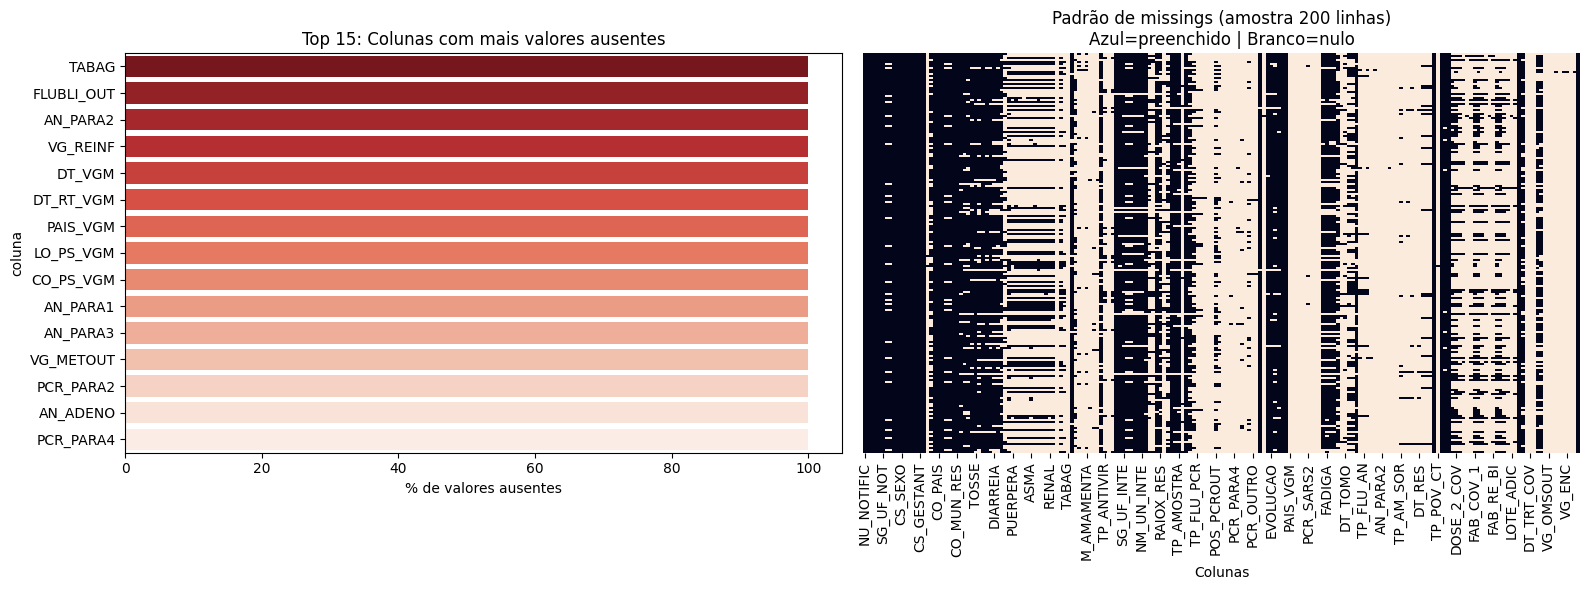

In [7]:
fill_rate_df = srag_df.notna().mean().mul(100).round(2).reset_index()
fill_rate_df.columns = ['coluna', 'fill_rate (%)']

print("Top 20 colunas mais preenchidas:")
display(fill_rate_df.sort_values('fill_rate (%)', ascending=False).head(20))
print(f"\nColunas completamente nulas: {srag_df.isna().all().sum()}")

# Visualização
percentual_nulos_series = (srag_df.isnull().mean() * 100).round(2)
resumo_ausentes = pd.DataFrame({
    'coluna': percentual_nulos_series.index,
    'percentual_nulos (%)': percentual_nulos_series.values
}).sort_values('percentual_nulos (%)', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=resumo_ausentes.head(15), x='percentual_nulos (%)', y='coluna',
            palette='Reds_r', ax=axes[0])
axes[0].set_title('Top 15: Colunas com mais valores ausentes')
axes[0].set_xlabel('% de valores ausentes')

amostra_heatmap = srag_df.isnull().sample(200, random_state=42)
sns.heatmap(amostra_heatmap, cbar=False, yticklabels=False, ax=axes[1])
axes[1].set_title('Padrão de missings (amostra 200 linhas)\nAzul=preenchido | Branco=nulo')
axes[1].set_xlabel('Colunas')

plt.tight_layout()
plt.show()


### 4.5 Remoção de Outliers

Idades negativas ou acima de 100 anos são biologicamente implausíveis.  
Registros com esses valores são removidos antes do pré-processamento.


Registros antes: 336,243

Distribuição da idade ANTES:


,NU_IDADE_N
count,336243.00
mean,30.01
std,32.43
min,-1.00
25%,3.00
50%,9.00
75%,64.00
max,141.00



Registros após remoção de outliers: 333,955

Distribuição da idade APÓS:


,NU_IDADE_N
count,333955.00
mean,30.12
std,32.38
min,1.00
25%,3.00
50%,9.00
75%,64.00
max,100.00


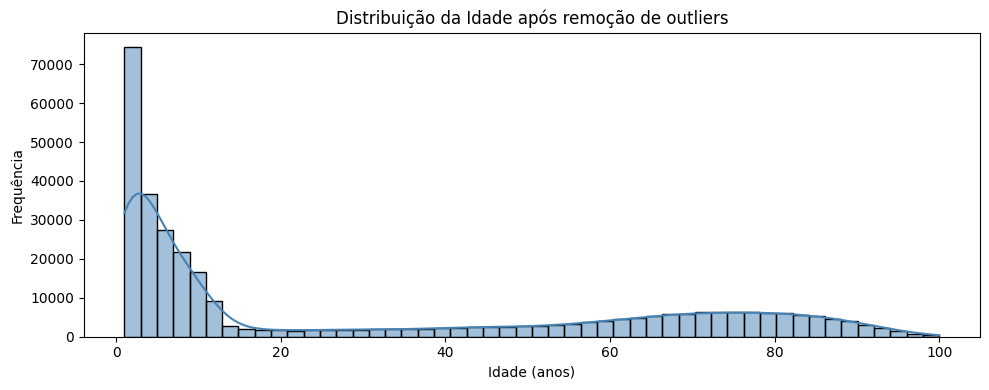

In [8]:
print(f"Registros antes: {len(srag_df):,}")
print("\nDistribuição da idade ANTES:")
display(srag_df['NU_IDADE_N'].describe().round(2))

# TP_IDADE = 1 → a unidade é "anos". Idades negativas ou > 100 são erros de digitação.
srag_df = srag_df[(srag_df['NU_IDADE_N'] > 0) & (srag_df['NU_IDADE_N'] <= 100)].copy()

print(f"\nRegistros após remoção de outliers: {len(srag_df):,}")
print("\nDistribuição da idade APÓS:")
display(srag_df['NU_IDADE_N'].describe().round(2))

plt.figure(figsize=(10, 4))
sns.histplot(srag_df['NU_IDADE_N'], bins=50, kde=True, color='steelblue')
plt.title('Distribuição da Idade após remoção de outliers')
plt.xlabel('Idade (anos)')
plt.ylabel('Frequência')
plt.tight_layout()
plt.show()


## 5. Pré-processamento

### 5.1 Criação da Variável Alvo

Mantemos apenas registros com desfecho definido: **Cura (EVOLUCAO=1)** ou **Óbito (EVOLUCAO=2)**.  
Registros com desfecho ignorado ou ainda em tratamento são excluídos.


In [9]:
srag_modelo = srag_df[srag_df['EVOLUCAO'].isin([1, 2])].copy()
srag_modelo['obito'] = (srag_modelo['EVOLUCAO'] == 2).astype(int)

print(f"Registros originais:         {len(srag_df):,}")
print(f"Após filtro (cura/óbito):    {len(srag_modelo):,}")
print(f"Removidos (sem desfecho):    {len(srag_df) - len(srag_modelo):,}")

qtd_cura   = (srag_modelo['obito'] == 0).sum()
qtd_obito  = (srag_modelo['obito'] == 1).sum()
target_dist = pd.DataFrame({
    'Desfecho': ['Cura', 'Óbito'],
    'Quantidade': [qtd_cura, qtd_obito],
    'Percentual (%)': [
        round(qtd_cura / len(srag_modelo) * 100, 2),
        round(qtd_obito / len(srag_modelo) * 100, 2)
    ]
})
display(target_dist)
print(f"\nTaxa de óbito: {srag_modelo['obito'].mean()*100:.1f}%  → BASE DESBALANCEADA")


Registros originais:         333,955
Após filtro (cura/óbito):    302,633
Removidos (sem desfecho):    31,322


,Desfecho,Quantidade,Percentual (%)
0,Cura,279818,92.46
1,Óbito,22815,7.54



Taxa de óbito: 7.5%  → BASE DESBALANCEADA


### 5.2 Extração de Features a partir de Texto Livre

As colunas `OUT_MORBI` e `MORB_DESC` contêm anotações livres dos médicos sobre comorbidades.  
Como `TABAG` (tabagismo) estava 100% vazia no dataset, e `DIABETES`/`OBESIDADE` tinham fill rate muito baixo,  
usamos busca por expressões regulares nesses campos de texto para criar variáveis binárias.


In [10]:
colunas_texto_clinico = ['OUT_MORBI', 'MORB_DESC']
colunas_existentes = [c for c in colunas_texto_clinico if c in srag_modelo.columns]
texto_clinico = srag_modelo[colunas_existentes].fillna('').astype(str).agg(' '.join, axis=1)

def extrair_tabagismo(texto):
    t = str(texto).upper()
    if re.search(r'(NEGA|NÃO|NAO|NUNCA)\s*(TABAG|FUMA|FUMO|CIGAR)', t):
        return 0
    elif re.search(r'TABAG|FUMA|CIGAR', t):
        return 1
    return 0

def extrair_diabetes(texto):
    t = str(texto).upper()
    if re.search(r'(NEGA|NÃO|NAO|SEM)\s*(DIABET|DM|DM2|DM1)', t):
        return 0
    elif re.search(r'DIABET|DM\b|DM2|DM1', t):
        return 1
    return 0

def extrair_obesidade(texto):
    t = str(texto).upper()
    if re.search(r'(NEGA|NÃO|NAO|SEM)\s*(OBES|SOBREPESO)', t):
        return 0
    elif re.search(r'OBES|SOBREPESO|IMC\s*(>|MAIOR|ELEVADO)', t):
        return 1
    return 0

srag_modelo['TABAG']    = texto_clinico.apply(extrair_tabagismo)
srag_modelo['DIABETES'] = texto_clinico.apply(extrair_diabetes)
srag_modelo['OBESIDADE']= texto_clinico.apply(extrair_obesidade)

for col in ['TABAG', 'DIABETES', 'OBESIDADE']:
    pos = srag_modelo[col].sum()
    print(f"{col:10s}: {pos:5,} positivos ({pos/len(srag_modelo)*100:.2f}%)")


TABAG     : 1,016 positivos (0.34%)
DIABETES  :   380 positivos (0.13%)
OBESIDADE :   167 positivos (0.06%)


### 5.3 Limpeza de Colunas

**Critérios de remoção:**
1. Colunas com mais de 70% de valores nulos (pouca informação útil para o modelo)
2. Colunas administrativas (identificadores, datas de registro) — sem valor preditivo
3. Colunas de texto livre usadas para extração (já processadas acima)


In [11]:
# Remove colunas de texto bruto (já extraídas)
srag_modelo = srag_modelo.drop(
    columns=[c for c in ['OUT_MORBI', 'MORB_DESC'] if c in srag_modelo.columns]
)

# Remove colunas com > 70% de nulos
limite_nulos = 70
percentual_nulos = (srag_modelo.isnull().mean() * 100).round(2)
colunas_remover_nulos = percentual_nulos[percentual_nulos > limite_nulos].index.tolist()
srag_modelo = srag_modelo.drop(columns=colunas_remover_nulos, errors='ignore')
print(f"Colunas removidas (>70% nulos): {len(colunas_remover_nulos)}")

# Remove colunas administrativas
colunas_adm = [
    'NU_NOTIFIC', 'DT_NOTIFIC', 'DT_SIN_PRI', 'DT_NASC',
    'DT_ENCERRA', 'DT_DIGITA', 'DT_EVOLUCA', 'DT_INTERNA',
    'CO_MUN_NOT', 'CO_UF_INTE', 'CO_MUN_INT', 'CO_CEP',
    'NU_LOTE_V', 'NU_LOTE_E', 'ID_REGIONA', 'ID_UNIDADE', 'EVOLUCAO'
]
colunas_adm_existentes = [c for c in colunas_adm if c in srag_modelo.columns]
srag_modelo = srag_modelo.drop(columns=colunas_adm_existentes, errors='ignore')
print(f"Colunas administrativas removidas: {len(colunas_adm_existentes)}")
print(f"\nShape após limpeza: {srag_modelo.shape}")


Colunas removidas (>70% nulos): 90
Colunas administrativas removidas: 11

Shape após limpeza: (302633, 92)


### 5.4 Seleção de Features

Selecionamos 28 variáveis clínicas e demográficas com base no conhecimento do domínio:
- **Demográficas:** idade, raça, gestação
- **Comorbidades:** cardiopatia, diabetes, asma, neurológica, renal, etc.
- **Sintomas:** febre, tosse, dispneia, saturação, etc.
- **Internação:** hospital, UTI, suporte ventilatório, antiviral
- **Classificação:** CLASSI_FIN (agente etiológico)


In [12]:
features_clinicas = [
    'NU_IDADE_N', 'CS_GESTANT', 'CS_RACA',
    'CARDIOPATI', 'HEMATOLOGI', 'HEPATICA', 'ASMA', 'DIABETES',
    'NEUROLOGIC', 'PNEUMOPATI', 'IMUNODEPRE', 'RENAL', 'OBESIDADE',
    'FEBRE', 'TOSSE', 'GARGANTA', 'DISPNEIA', 'DESC_RESP',
    'SATURACAO', 'DIARREIA', 'VOMITO', 'FADIGA',
    'HOSPITAL', 'UTI', 'SUPORT_VEN', 'ANTIVIRAL',
    'CLASSI_FIN', 'TABAG'
]

features_existentes = [c for c in features_clinicas if c in srag_modelo.columns]
features_faltando   = [c for c in features_clinicas if c not in srag_modelo.columns]

print(f"Features selecionadas: {len(features_existentes)}")
if features_faltando:
    print(f"Features não encontradas na base: {features_faltando}")

df_modelo = srag_modelo[features_existentes + ['obito']].copy()
print(f"\nShape do dataframe de modelagem: {df_modelo.shape}")
display(df_modelo.head())


Features selecionadas: 28

Shape do dataframe de modelagem: (302633, 29)


,NU_IDADE_N,CS_GESTANT,CS_RACA,CARDIOPATI,HEMATOLOGI,HEPATICA,ASMA,DIABETES,NEUROLOGIC,PNEUMOPATI,IMUNODEPRE,RENAL,OBESIDADE,FEBRE,TOSSE,GARGANTA,DISPNEIA,DESC_RESP,SATURACAO,DIARREIA,VOMITO,FADIGA,HOSPITAL,UTI,SUPORT_VEN,ANTIVIRAL,CLASSI_FIN,TABAG,obito
0,7,6,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,0,1.0,1.0,NaN,1.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,3.0,NaN,4.0,0,0
1,18,6,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,0,2.0,1.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,0,0
3,58,5,4,NaN,NaN,NaN,1.0,0,NaN,NaN,NaN,NaN,0,NaN,1.0,NaN,NaN,1.0,1.0,NaN,NaN,NaN,1.0,NaN,NaN,NaN,4.0,0,0
5,53,6,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,0,0
6,45,5,4,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,1,1.0,1.0,NaN,1.0,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,2.0,4.0,0,0


### 5.5 Correção de Tipos e Imputação

In [13]:
# Booleanos → inteiros
colunas_bool = df_modelo.select_dtypes(include='bool').columns.tolist()
df_modelo[colunas_bool] = df_modelo[colunas_bool].astype(int)

# Colunas derivadas de texto → int
for col in ['TABAG', 'DIABETES', 'OBESIDADE']:
    if col in df_modelo.columns:
        df_modelo[col] = df_modelo[col].astype(int)

# Object → numérico (alguns códigos ficam como string)
for col in df_modelo.select_dtypes(include='object').columns:
    df_modelo[col] = pd.to_numeric(df_modelo[col], errors='coerce')

# Imputa NaN com a moda (valor mais frequente por coluna)
if df_modelo.isnull().sum().sum() > 0:
    df_modelo = df_modelo.fillna(df_modelo.mode().iloc[0])

print(f"Shape: {df_modelo.shape}")
print(f"Nulos restantes: {df_modelo.isnull().sum().sum()}")
display(df_modelo.dtypes.value_counts().reset_index())


Shape: (302633, 29)
Nulos restantes: 0


,index,count
0,float64,22
1,int64,7


## 6. Análise do Desbalanceamento de Classes

A variável alvo `obito` é fortemente desbalanceada: apenas ~7.5% dos casos são óbito.  
Isso afeta diretamente o treinamento — modelos tendem a prever sempre "Cura" e ainda assim obter alta acurácia.  
Usaremos métricas como **ROC-AUC**, **PR-AUC** e **Recall** que são mais informativas nesse cenário.


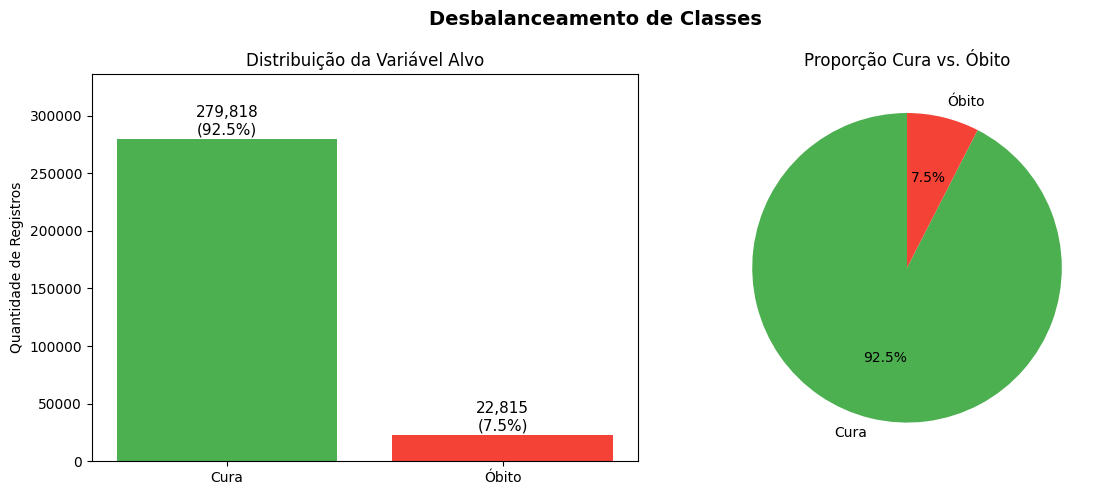

In [14]:
dist_obito = df_modelo['obito'].value_counts().reset_index()
dist_obito.columns = ['classe', 'quantidade']
dist_obito['percentual (%)'] = (dist_obito['quantidade'] / len(df_modelo) * 100).round(2)
dist_obito['Desfecho'] = dist_obito['classe'].map({0: 'Cura', 1: 'Óbito'})

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cores = ['#4CAF50', '#F44336']
axes[0].bar(dist_obito['Desfecho'], dist_obito['quantidade'], color=cores)
for i, row in dist_obito.iterrows():
    axes[0].text(i, row['quantidade'] + 1000,
                 f"{row['quantidade']:,}\n({row['percentual (%)']:.1f}%)",
                 ha='center', va='bottom', fontsize=11)
axes[0].set_title('Distribuição da Variável Alvo')
axes[0].set_ylabel('Quantidade de Registros')
axes[0].set_ylim(0, dist_obito['quantidade'].max() * 1.2)

axes[1].pie(dist_obito['quantidade'], labels=dist_obito['Desfecho'],
            autopct='%1.1f%%', colors=cores, startangle=90)
axes[1].set_title('Proporção Cura vs. Óbito')

plt.suptitle('Desbalanceamento de Classes', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 7. Divisão Treino / Teste

Para os modelos baseline usamos divisão 80/20 com estratificação (mantém a proporção de óbitos em ambos os conjuntos).


In [15]:
X = df_modelo.drop(columns=['obito'])
y = df_modelo['obito']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Treino: {X_train.shape[0]:,} registros | {X_train.shape[1]} features")
print(f"Teste:  {X_test.shape[0]:,} registros | {X_test.shape[1]} features")
print(f"\nTaxa de óbito no treino: {y_train.mean()*100:.1f}%")
print(f"Taxa de óbito no teste:  {y_test.mean()*100:.1f}%")

# thresholds compartilhado pelos modelos baseline
thresholds = np.arange(0.1, 0.9, 0.01)


Treino: 242,106 registros | 28 features
Teste:  60,527 registros | 28 features

Taxa de óbito no treino: 7.5%
Taxa de óbito no teste:  7.5%


## 8. Modelos Baseline

### 8.1 Árvore de Decisão

Primeiro modelo treinado — utlizado para explorar quais variáveis o modelo considera mais importantes antes de normalizações.  
`class_weight='balanced'` compensa o desbalanceamento durante o treinamento.


> **Nota metodológica:** nesta fase, o threshold é otimizado diretamente no conjunto de teste para fins de comparação dos modelos baseline. Esta abordagem possui *data leakage* leve (o teste influencia a escolha do ponto de corte). A versão metodologicamente correta — com conjunto de validação separado — está na **Seção 11**.

In [16]:
arvore = DecisionTreeClassifier(
    max_depth=4, min_samples_leaf=50, class_weight='balanced', random_state=42
)
arvore.fit(X_train, y_train)
y_prob_tree = arvore.predict_proba(X_test)[:, 1]

f1s_tree = [f1_score(y_test, y_prob_tree >= t) for t in thresholds]
best_thresh_tree = thresholds[np.argmax(f1s_tree)]
y_pred_tree = (y_prob_tree >= best_thresh_tree).astype(int)

print("=== Árvore de Decisão ===")
print(f"Melhor threshold (F1 máx): {best_thresh_tree:.2f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_tree):.4f}")
print(f"PR-AUC:  {average_precision_score(y_test, y_prob_tree):.4f}")
print(classification_report(y_test, y_pred_tree, target_names=['Cura', 'Óbito']))
print("Matriz de confusão:")
print(confusion_matrix(y_test, y_pred_tree))


=== Árvore de Decisão ===
Melhor threshold (F1 máx): 0.77
ROC-AUC: 0.8763
PR-AUC:  0.3686
              precision    recall  f1-score   support

        Cura       0.95      0.97      0.96     55964
       Óbito       0.53      0.38      0.44      4563

    accuracy                           0.93     60527
   macro avg       0.74      0.67      0.70     60527
weighted avg       0.92      0.93      0.92     60527

Matriz de confusão:
[[54423  1541]
 [ 2846  1717]]


#### Importância de Features e Visualização da Árvore

Top 10 features — Árvore de Decisão:


,feature,importancia
0,NU_IDADE_N,0.758587
24,SUPORT_VEN,0.236783
23,UTI,0.002570
3,CARDIOPATI,0.001604
6,ASMA,0.000246
26,CLASSI_FIN,0.000211
2,CS_RACA,0.000000
7,DIABETES,0.000000
8,NEUROLOGIC,0.000000
4,HEMATOLOGI,0.000000


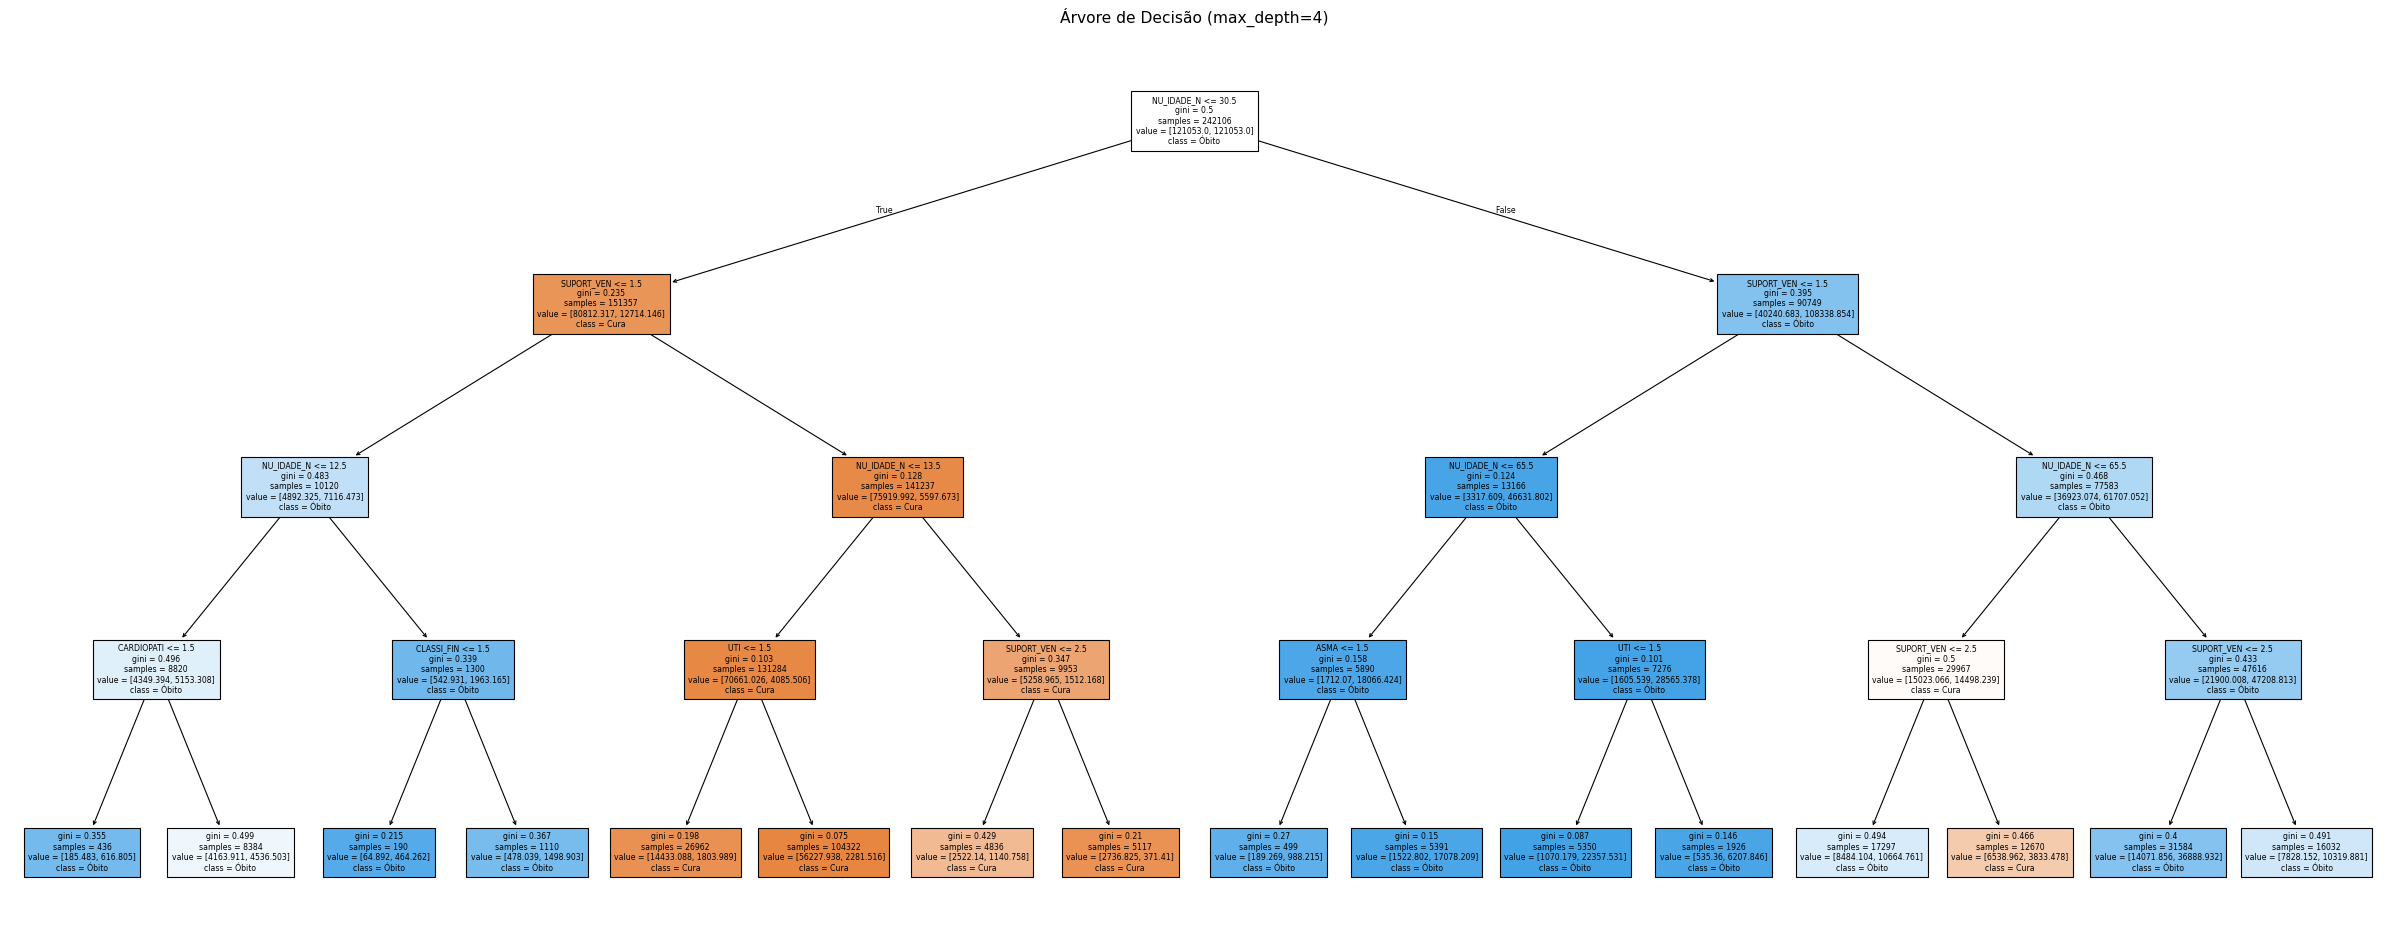

In [17]:
importancias_tree = pd.DataFrame({
    'feature': X_train.columns,
    'importancia': arvore.feature_importances_
}).sort_values('importancia', ascending=False)

print("Top 10 features — Árvore de Decisão:")
display(importancias_tree.head(10))

plt.figure(figsize=(30, 12), dpi=80)
plot_tree(arvore, feature_names=X_train.columns.tolist(),
          class_names=['Cura', 'Óbito'], filled=True, fontsize=7)
plt.title("Árvore de Decisão (max_depth=4)", fontsize=14)
plt.tight_layout()
plt.show()


### 8.2 Regressão Logística

A Regressão Logística foi escolhida como segundo baseline por ser interpretável (os coeficientes têm sentido direto de risco) e por produzir probabilidades calibradas.

O pipeline inclui `StandardScaler` porque a Regressão Logística usa gradiente descendente: features em escalas muito diferentes (ex.: `NU_IDADE_N` em anos vs. variáveis binárias 0/1) causam convergência lenta e coeficientes mal estimados. Modelos baseados em árvores (Árvore de Decisão, LightGBM, XGBoost) são invariantes à escala e por isso não precisam de normalização.

In [18]:
pipeline_lr = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=5000, random_state=42))
])
pipeline_lr.fit(X_train, y_train)
y_prob_lr = pipeline_lr.predict_proba(X_test)[:, 1]

f1s_lr = [f1_score(y_test, y_prob_lr >= t) for t in thresholds]
best_thresh_lr = thresholds[np.argmax(f1s_lr)]
y_pred_lr = (y_prob_lr >= best_thresh_lr).astype(int)

print("=== Regressão Logística ===")
print(f"Melhor threshold: {best_thresh_lr:.2f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_lr):.4f}")
print(f"PR-AUC:  {average_precision_score(y_test, y_prob_lr):.4f}")
print(classification_report(y_test, y_pred_lr, target_names=['Cura', 'Óbito']))

coef_df = pd.DataFrame({
    'feature': X_train.columns,
    'coeficiente': pipeline_lr.named_steps['clf'].coef_[0]
}).sort_values('coeficiente', ascending=False)
print("\nTop 10 features com maior coeficiente (↑ risco de óbito):")
display(coef_df.head(10))


=== Regressão Logística ===
Melhor threshold: 0.79
ROC-AUC: 0.8676
PR-AUC:  0.3481
              precision    recall  f1-score   support

        Cura       0.96      0.93      0.94     55964
       Óbito       0.37      0.48      0.42      4563

    accuracy                           0.90     60527
   macro avg       0.66      0.71      0.68     60527
weighted avg       0.91      0.90      0.90     60527


Top 10 features com maior coeficiente (↑ risco de óbito):


,feature,coeficiente
0,NU_IDADE_N,1.285073
14,TOSSE,0.283801
22,HOSPITAL,0.217980
6,ASMA,0.161197
25,ANTIVIRAL,0.118348
15,GARGANTA,0.108262
4,HEMATOLOGI,0.054338
20,VOMITO,0.042772
13,FEBRE,0.028045
5,HEPATICA,0.017790


### 8.3 LightGBM

LightGBM é um algoritmo de *gradient boosting* baseado em árvores de decisão construídas sequencialmente, onde cada nova árvore corrige os erros residuais da anterior. Foi incluído por ser computacionalmente eficiente em datasets grandes (usa histogramas de features em vez de ordenação completa) e por geralmente superar Regressão Logística e Árvore simples em tarefas clínicas complexas.

O parâmetro `scale_pos_weight` aplica um peso maior à classe minoritária (óbito) durante o cálculo do gradiente, funcionando como alternativa ao resampling.

In [19]:
peso_manual = len(y_train[y_train == 0]) / len(y_train[y_train == 1])

lgbm = LGBMClassifier(
    n_estimators=300, learning_rate=0.01, max_depth=12,
    scale_pos_weight=peso_manual, subsample=0.8, colsample_bytree=0.8,
    random_state=42, verbose=-1
)
lgbm.fit(X_train, y_train)
y_prob_lgbm = lgbm.predict_proba(X_test)[:, 1]

f1s_lgbm = [f1_score(y_test, y_prob_lgbm >= t) for t in thresholds]
best_thresh_lgbm = thresholds[np.argmax(f1s_lgbm)]
y_pred_lgbm = (y_prob_lgbm >= best_thresh_lgbm).astype(int)

print("=== LightGBM ===")
print(f"Melhor threshold: {best_thresh_lgbm:.2f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_lgbm):.4f}")
print(f"PR-AUC:  {average_precision_score(y_test, y_prob_lgbm):.4f}")
print(classification_report(y_test, y_pred_lgbm, target_names=['Cura', 'Óbito']))


=== LightGBM ===
Melhor threshold: 0.73
ROC-AUC: 0.9030
PR-AUC:  0.4664
              precision    recall  f1-score   support

        Cura       0.96      0.94      0.95     55964
       Óbito       0.44      0.54      0.49      4563

    accuracy                           0.91     60527
   macro avg       0.70      0.74      0.72     60527
weighted avg       0.92      0.91      0.92     60527



### 8.4 Comparação dos Modelos Baseline

=== Resultados dos Modelos Baseline ===


,Modelo,ROC-AUC,PR-AUC,F1 (óbito),Recall,Precision,Threshold
2,LightGBM,0.9030,0.4664,0.4854,0.5428,0.4390,0.73
0,Árvore de Decisão,0.8763,0.3686,0.4391,0.3763,0.5270,0.77
1,Regressão Logística,0.8676,0.3481,0.4153,0.4793,0.3663,0.79


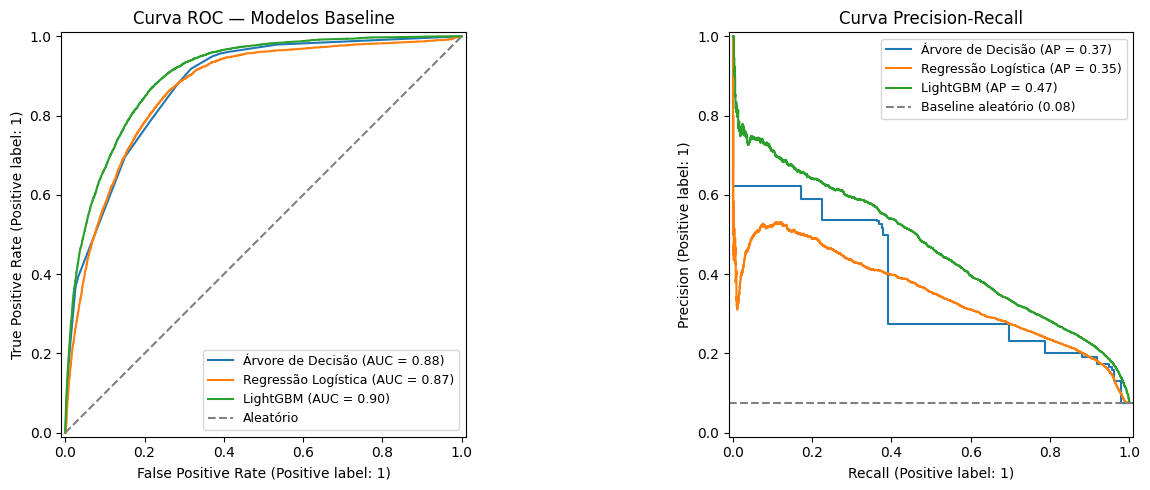

In [20]:
modelos_baseline = {
    'Árvore de Decisão': (y_prob_tree, best_thresh_tree),
    'Regressão Logística': (y_prob_lr, best_thresh_lr),
    'LightGBM': (y_prob_lgbm, best_thresh_lgbm),
}

resultados = []
for nome, (probs, thr) in modelos_baseline.items():
    preds = (probs >= thr).astype(int)
    resultados.append({
        'Modelo': nome,
        'ROC-AUC': round(roc_auc_score(y_test, probs), 4),
        'PR-AUC': round(average_precision_score(y_test, probs), 4),
        'F1 (óbito)': round(f1_score(y_test, preds), 4),
        'Recall': round(recall_score(y_test, preds), 4),
        'Precision': round(precision_score(y_test, preds), 4),
        'Threshold': round(thr, 2),
    })

resultados_df = pd.DataFrame(resultados).sort_values('PR-AUC', ascending=False)
print("=== Resultados dos Modelos Baseline ===")
display(resultados_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for nome, (probs, _) in modelos_baseline.items():
    RocCurveDisplay.from_predictions(y_test, probs, ax=axes[0], name=nome)
axes[0].plot([0,1],[0,1],'--', color='gray', label='Aleatório')
axes[0].set_title("Curva ROC — Modelos Baseline")
axes[0].legend(fontsize=9)

for nome, (probs, _) in modelos_baseline.items():
    PrecisionRecallDisplay.from_predictions(y_test, probs, ax=axes[1], name=nome)
axes[1].axhline(y=y_test.mean(), color='gray', linestyle='--',
                label=f'Baseline aleatório ({y_test.mean():.2f})')
axes[1].set_title("Curva Precision-Recall")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()


#### Leitura dos Resultados — Modelos Baseline

Entre os três modelos baseline, o **LightGBM obteve o maior ROC-AUC e PR-AUC**, confirmando que modelos de *gradient boosting* capturam melhor as relações não-lineares entre variáveis clínicas e desfecho.

A **Árvore de Decisão** apresentou maior Precision mas menor Recall — ela é conservadora: só sinaliza óbito quando tem alta certeza, mas perde muitos casos reais.

A **Regressão Logística**, por sua vez, conseguiu Recall razoável ao custo de menor Precision, o que é esperado com `class_weight='balanced'`.

Estes resultados motivam o uso de XGBoost (também *gradient boosting*) combinado com técnicas de balanceamento na próxima etapa.

## 9. Técnicas de Balanceamento

Testamos três estratégias para lidar com o desbalanceamento 92.5% Cura / 7.5% Óbito:

| Técnica | Descrição |
|---------|-----------|
| **RUS** (Random Undersampling) | Reduz a classe majoritária aleatoriamente |
| **SMOTE** (Oversampling) | Gera amostras sintéticas da classe minoritária por interpolação KNN |
| **SMOTEENN** (Híbrido) | SMOTE + ENN para limpeza de ruído na fronteira de decisão |

**Importante:** o balanceamento é aplicado APENAS no conjunto de treino para evitar data leakage.


**Limitação importante do SMOTE:** as amostras geradas são interpolações lineares entre pontos reais no espaço de features — elas não correspondem a pacientes reais. Em contexto clínico, isso pode introduzir combinações de sintomas e comorbidades biologicamente implausíveis. Por isso, avaliamos também o `scale_pos_weight` do XGBoost como alternativa sem geração sintética.

In [21]:
rus      = RandomUnderSampler(random_state=42)
smote    = SMOTE(random_state=42)
smoteenn = SMOTEENN(random_state=42)

X_train_rus,   y_train_rus   = rus.fit_resample(X_train, y_train)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
X_train_sme,   y_train_sme   = smoteenn.fit_resample(X_train, y_train)

print(f"Original:  {X_train.shape[0]:>7,} amostras | Óbito: {y_train.sum():,} ({y_train.mean()*100:.1f}%)")
print(f"RUS:       {X_train_rus.shape[0]:>7,} amostras | Óbito: {y_train_rus.sum():,} ({y_train_rus.mean()*100:.1f}%)")
print(f"SMOTE:     {X_train_smote.shape[0]:>7,} amostras | Óbito: {y_train_smote.sum():,} ({y_train_smote.mean()*100:.1f}%)")
print(f"SMOTEENN:  {X_train_sme.shape[0]:>7,} amostras | Óbito: {y_train_sme.sum():,} ({y_train_sme.mean()*100:.1f}%)")


Original:  242,106 amostras | Óbito: 18,252 (7.5%)
RUS:        36,504 amostras | Óbito: 18,252 (50.0%)
SMOTE:     447,708 amostras | Óbito: 223,854 (50.0%)
SMOTEENN:  387,001 amostras | Óbito: 207,680 (53.7%)


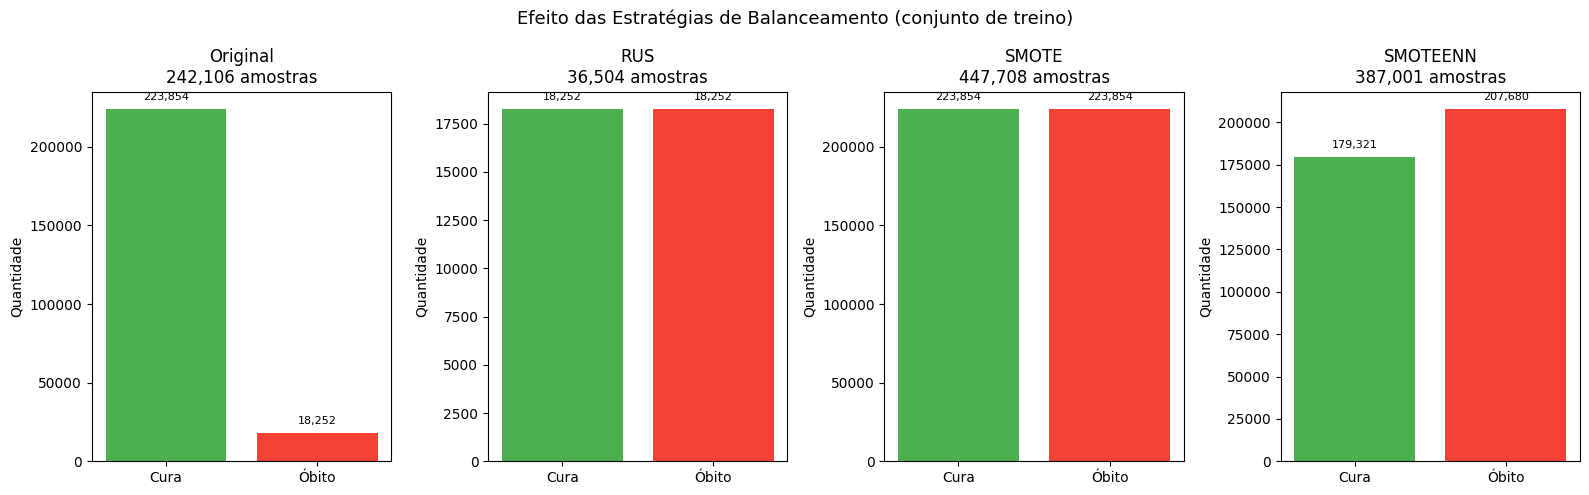

In [22]:
estrategias_bal = {
    'Original': y_train,
    'RUS': y_train_rus,
    'SMOTE': y_train_smote,
    'SMOTEENN': y_train_sme
}

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for ax, (nome, y_b) in zip(axes, estrategias_bal.items()):
    counts = y_b.value_counts()
    ax.bar(['Cura', 'Óbito'], [counts.get(0, 0), counts.get(1, 0)],
           color=['#4CAF50', '#F44336'])
    ax.set_title(f'{nome}\n{len(y_b):,} amostras')
    ax.set_ylabel('Quantidade')
    for i, cnt in enumerate([counts.get(0, 0), counts.get(1, 0)]):
        ax.text(i, cnt + max(counts.values)*0.02, f'{cnt:,}',
                ha='center', va='bottom', fontsize=8)

plt.suptitle('Efeito das Estratégias de Balanceamento (conjunto de treino)', fontsize=13)
plt.tight_layout()
plt.show()


## 10. XGBoost com Diferentes Estratégias de Balanceamento

O LightGBM superou os outros baselines, o que sugere que *gradient boosting* é o paradigma mais adequado para este problema. Testamos aqui o **XGBoost** — outra implementação de *gradient boosting*, amplamente adotada em competições de dados clínicos — combinado com as três estratégias de balanceamento definidas na seção anterior.

O objetivo é separar o efeito do algoritmo do efeito do balanceamento: mantemos o XGBoost fixo e variamos apenas como o conjunto de treino é preparado.

In [23]:
def treinar_xgb(X_tr, y_tr, X_te, y_te, nome):
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', XGBClassifier(
            objective='binary:logistic', eval_metric='logloss',
            random_state=42, n_estimators=300,
            learning_rate=0.05, max_depth=5
        ))
    ])
    pipe.fit(X_tr, y_tr)
    probs = pipe.predict_proba(X_te)[:, 1]

    prec, rec, thr_pr = precision_recall_curve(y_te, probs)
    f1s = 2 * prec * rec / (prec + rec + 1e-10)
    best_thr = thr_pr[np.argmax(f1s)]
    preds = (probs >= best_thr).astype(int)

    print(f"\n=== XGBoost + {nome} ===")
    print(f"ROC-AUC: {roc_auc_score(y_te, probs):.4f}  |  "
          f"PR-AUC: {average_precision_score(y_te, probs):.4f}  |  "
          f"Threshold: {best_thr:.4f}")
    print(classification_report(y_te, preds, target_names=['Cura', 'Óbito']))
    return pipe, probs, best_thr

pipeline_xgb_rus,   y_prob_xgb_rus,   best_thresh_xgb_rus   = treinar_xgb(
    X_train_rus,   y_train_rus,   X_test, y_test, "RUS")
pipeline_xgb_smote, y_prob_xgb_smote, best_thresh_xgb_smote = treinar_xgb(
    X_train_smote, y_train_smote, X_test, y_test, "SMOTE")
pipeline_xgb_sme,   y_prob_xgb_sme,   best_thresh_xgb_sme   = treinar_xgb(
    X_train_sme,   y_train_sme,   X_test, y_test, "SMOTEENN")



=== XGBoost + RUS ===
ROC-AUC: 0.9031  |  PR-AUC: 0.4713  |  Threshold: 0.8152
              precision    recall  f1-score   support

        Cura       0.96      0.95      0.96     55964
       Óbito       0.47      0.50      0.49      4563

    accuracy                           0.92     60527
   macro avg       0.71      0.73      0.72     60527
weighted avg       0.92      0.92      0.92     60527


=== XGBoost + SMOTE ===
ROC-AUC: 0.8936  |  PR-AUC: 0.4405  |  Threshold: 0.4260
              precision    recall  f1-score   support

        Cura       0.96      0.94      0.95     55964
       Óbito       0.42      0.52      0.46      4563

    accuracy                           0.91     60527
   macro avg       0.69      0.73      0.71     60527
weighted avg       0.92      0.91      0.91     60527


=== XGBoost + SMOTEENN ===
ROC-AUC: 0.9014  |  PR-AUC: 0.4594  |  Threshold: 0.6605
              precision    recall  f1-score   support

        Cura       0.96      0.94      0.95 

### 10.1 Comparação de Todos os Modelos

=== Comparação Geral de Todos os Modelos ===


,Modelo,ROC-AUC,PR-AUC,F1 (óbito),Recall,Precision,Threshold
3,XGBoost + RUS,0.9031,0.4713,0.4870,0.5049,0.4703,0.8152
2,LightGBM,0.9030,0.4664,0.4854,0.5428,0.4390,0.7300
5,XGBoost + SMOTEENN,0.9014,0.4594,0.4839,0.5404,0.4381,0.6605
4,XGBoost + SMOTE,0.8936,0.4405,0.4617,0.5152,0.4182,0.4260
0,Árvore de Decisão,0.8763,0.3686,0.4391,0.3763,0.5270,0.7700
1,Regressão Logística,0.8676,0.3481,0.4153,0.4793,0.3663,0.7900


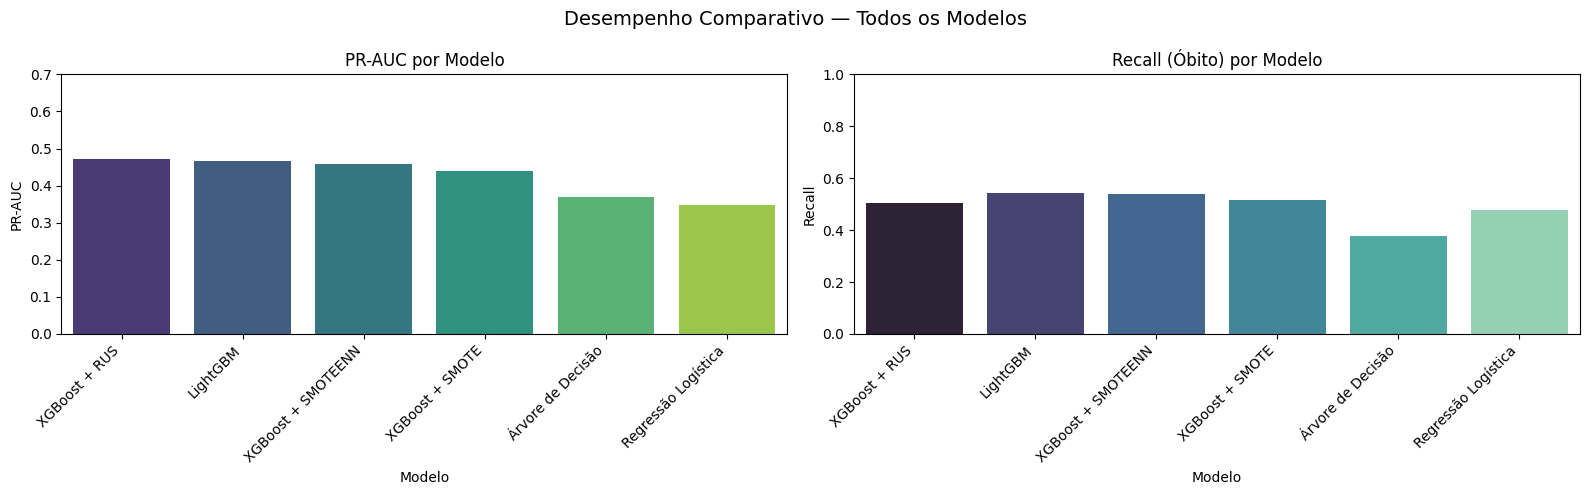

In [24]:
modelos_xgb = {
    'XGBoost + RUS':      (y_prob_xgb_rus,   best_thresh_xgb_rus),
    'XGBoost + SMOTE':    (y_prob_xgb_smote, best_thresh_xgb_smote),
    'XGBoost + SMOTEENN': (y_prob_xgb_sme,   best_thresh_xgb_sme),
}

resultados_xgb = []
for nome, (probs, thr) in modelos_xgb.items():
    preds = (probs >= thr).astype(int)
    resultados_xgb.append({
        'Modelo': nome,
        'ROC-AUC':    round(roc_auc_score(y_test, probs), 4),
        'PR-AUC':     round(average_precision_score(y_test, probs), 4),
        'F1 (óbito)': round(f1_score(y_test, preds), 4),
        'Recall':     round(recall_score(y_test, preds), 4),
        'Precision':  round(precision_score(y_test, preds), 4),
        'Threshold':  round(thr, 4),
    })

todos_resultados = resultados + resultados_xgb
df_todos = pd.DataFrame(todos_resultados).sort_values('PR-AUC', ascending=False)
print("=== Comparação Geral de Todos os Modelos ===")
display(df_todos)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(data=df_todos, x='Modelo', y='PR-AUC', palette='viridis', ax=axes[0])
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
axes[0].set_title('PR-AUC por Modelo')
axes[0].set_ylim(0, 0.7)

sns.barplot(data=df_todos, x='Modelo', y='Recall', palette='mako', ax=axes[1])
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
axes[1].set_title('Recall (Óbito) por Modelo')
axes[1].set_ylim(0, 1)

plt.suptitle('Desempenho Comparativo — Todos os Modelos', fontsize=14)
plt.tight_layout()
plt.show()


### 10.2 Importância das Features — XGBoost + RUS

Top 20 features — XGBoost + RUS:


,feature,importancia
24,SUPORT_VEN,0.277080
0,NU_IDADE_N,0.269242
22,HOSPITAL,0.047401
14,TOSSE,0.045563
23,UTI,0.041174
8,NEUROLOGIC,0.031303
6,ASMA,0.023235
10,IMUNODEPRE,0.022071
17,DESC_RESP,0.019513
3,CARDIOPATI,0.018265


<Figure size 1000x800 with 0 Axes>

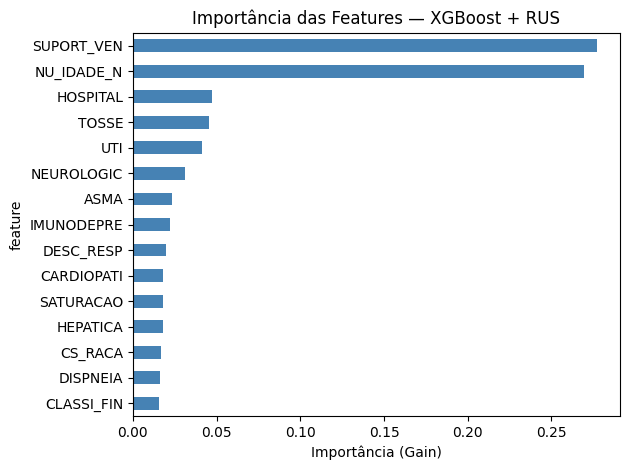

In [25]:
modelo_xgb_obj = pipeline_xgb_rus.named_steps['clf']
importancia_df = pd.DataFrame({
    'feature': X_train.columns,
    'importancia': modelo_xgb_obj.feature_importances_
}).sort_values('importancia', ascending=False)

print("Top 20 features — XGBoost + RUS:")
display(importancia_df.head(20))

plt.figure(figsize=(10, 8))
importancia_df.head(15).sort_values('importancia').plot(
    kind='barh', x='feature', y='importancia', color='steelblue', legend=False
)
plt.title('Importância das Features — XGBoost + RUS')
plt.xlabel('Importância (Gain)')
plt.tight_layout()
plt.show()


#### Interpretação da Importância das Features

Os dois fatores com maior peso — **SUPORT_VEN** (suporte ventilatório) e **NU_IDADE_N** (idade) — têm sentido clínico imediato: pacientes que necessitam de ventilação mecânica já estão em estado grave, e idade avançada é fator de risco amplamente documentado para SRAG.

As features de **comorbidades** (NEUROLOGIC, IMUNODEPRE, HEPATICA) aparecem com peso menor, o que é esperado dado o alto percentual de valores ausentes nessas colunas (~65-70%): após a imputação pela moda, a variabilidade real dessas variáveis é reduzida artificialmente.

Essa análise reforça que o modelo captura principalmente **indicadores de gravidade** (ventilação, idade, internação em UTI) em vez de fatores de risco pré-internação.

## 11. Modelo Final — Pipeline Corrigido

### Motivação

Nos experimentos anteriores, usamos o conjunto de teste para selecionar o threshold — isso constitui **data leakage**.  
A versão corrigida usa a seguinte estratégia:

1. **Treino (70%)** → treina o modelo
2. **Validação (15%)** → escolhe o melhor threshold
3. **Teste (15%)** → avalia o modelo apenas uma vez, com o threshold já fixado

Isso garante que o conjunto de teste permaneça "intocado" durante o desenvolvimento.


In [26]:
X_all = df_modelo.drop(columns=['obito'])
y_all = df_modelo['obito']

# 70 / 15 / 15
X_train_f, X_temp_f, y_train_f, y_temp_f = train_test_split(
    X_all, y_all, test_size=0.30, random_state=42, stratify=y_all
)
X_val_f, X_test_f, y_val_f, y_test_f = train_test_split(
    X_temp_f, y_temp_f, test_size=0.50, random_state=42, stratify=y_temp_f
)

print("=== DIVISÃO FINAL ===")
print(f"Treino:    {X_train_f.shape[0]:,} ({X_train_f.shape[0]/len(X_all)*100:.0f}%)")
print(f"Validação: {X_val_f.shape[0]:,} ({X_val_f.shape[0]/len(X_all)*100:.0f}%)")
print(f"Teste:     {X_test_f.shape[0]:,} ({X_test_f.shape[0]/len(X_all)*100:.0f}%)")
print(f"\nTaxa de óbito — treino: {y_train_f.mean()*100:.1f}%"
      f" | val: {y_val_f.mean()*100:.1f}% | teste: {y_test_f.mean()*100:.1f}%")

# Pesa a classe minoritária inversamente à sua frequência
scale_pos_weight = y_train_f.value_counts()[0] / y_train_f.value_counts()[1]
print(f"\nscale_pos_weight: {scale_pos_weight:.2f} "
      f"(cada óbito equivale a {scale_pos_weight:.1f} curas para o gradiente)")

xgb_final = XGBClassifier(
    objective='binary:logistic', eval_metric='logloss',
    random_state=42, n_estimators=300, learning_rate=0.05,
    max_depth=5, scale_pos_weight=scale_pos_weight
)
xgb_final.fit(X_train_f, y_train_f)
print("\nModelo final treinado com sucesso!")


=== DIVISÃO FINAL ===
Treino:    211,843 (70%)
Validação: 45,395 (15%)
Teste:     45,395 (15%)

Taxa de óbito — treino: 7.5% | val: 7.5% | teste: 7.5%

scale_pos_weight: 12.27 (cada óbito equivale a 12.3 curas para o gradiente)

Modelo final treinado com sucesso!


In [27]:
# Threshold escolhido na VALIDAÇÃO (não no teste)
y_prob_val = xgb_final.predict_proba(X_val_f)[:, 1]
prec_v, rec_v, thr_v = precision_recall_curve(y_val_f, y_prob_val)
f1s_v = 2 * prec_v * rec_v / (prec_v + rec_v + 1e-10)
best_thr_final = thr_v[np.argmax(f1s_v)]

print(f"=== THRESHOLD OTIMIZADO NA VALIDAÇÃO ===")
print(f"Melhor threshold:     {best_thr_final:.4f}")
print(f"Precision (val):      {prec_v[np.argmax(f1s_v)]:.4f}")
print(f"Recall    (val):      {rec_v[np.argmax(f1s_v)]:.4f}")
print(f"F1        (val):      {f1s_v.max():.4f}")

# Avaliação final no TESTE
y_prob_test_f = xgb_final.predict_proba(X_test_f)[:, 1]
y_pred_test_f = (y_prob_test_f >= best_thr_final).astype(int)

print(f"\n=== AVALIAÇÃO FINAL NO CONJUNTO DE TESTE ===")
print(f"Threshold usado: {best_thr_final:.4f}")
print(f"ROC-AUC:         {roc_auc_score(y_test_f, y_prob_test_f):.4f}")
print(f"PR-AUC:          {average_precision_score(y_test_f, y_prob_test_f):.4f}")
print()
print(classification_report(y_test_f, y_pred_test_f, target_names=['Cura', 'Óbito']))


=== THRESHOLD OTIMIZADO NA VALIDAÇÃO ===
Melhor threshold:     0.8098
Precision (val):      0.4704
Recall    (val):      0.5077
F1        (val):      0.4883

=== AVALIAÇÃO FINAL NO CONJUNTO DE TESTE ===
Threshold usado: 0.8098
ROC-AUC:         0.9028
PR-AUC:          0.4799

              precision    recall  f1-score   support

        Cura       0.96      0.95      0.96     41973
       Óbito       0.47      0.51      0.49      3422

    accuracy                           0.92     45395
   macro avg       0.72      0.73      0.72     45395
weighted avg       0.92      0.92      0.92     45395



### 11.1 Análise com Threshold Alternativo (0.5 — prioriza Recall)

O threshold ótimo pelo F1 maximiza o equilíbrio entre Precision e Recall. No entanto, em triagem clínica o custo de um **falso negativo** (paciente em risco não detectado) tende a ser maior que o custo de um **falso positivo** (alarme desnecessário).

O threshold 0.5 é testado como alternativa deliberadamente conservadora: com `scale_pos_weight` já aplicado, o modelo calibra sua probabilidade para favorecer a classe de óbito, de modo que 0.5 já representa um ponto de corte relativamente baixo na saída bruta do modelo — resultando em maior Recall ao custo de menor Precision.

In [28]:
threshold_alt = 0.5
y_pred_alt = (y_prob_test_f >= threshold_alt).astype(int)

print(f"=== THRESHOLD {threshold_alt} (prioriza Recall) ===")
print(f"ROC-AUC: {roc_auc_score(y_test_f, y_prob_test_f):.4f}")
print(f"PR-AUC:  {average_precision_score(y_test_f, y_prob_test_f):.4f}")
print()
print(classification_report(y_test_f, y_pred_alt, target_names=['Cura', 'Óbito']))


=== THRESHOLD 0.5 (prioriza Recall) ===
ROC-AUC: 0.9028
PR-AUC:  0.4799

              precision    recall  f1-score   support

        Cura       0.98      0.79      0.88     41973
       Óbito       0.25      0.85      0.39      3422

    accuracy                           0.80     45395
   macro avg       0.62      0.82      0.63     45395
weighted avg       0.93      0.80      0.84     45395



## 12. Visualizações Finais

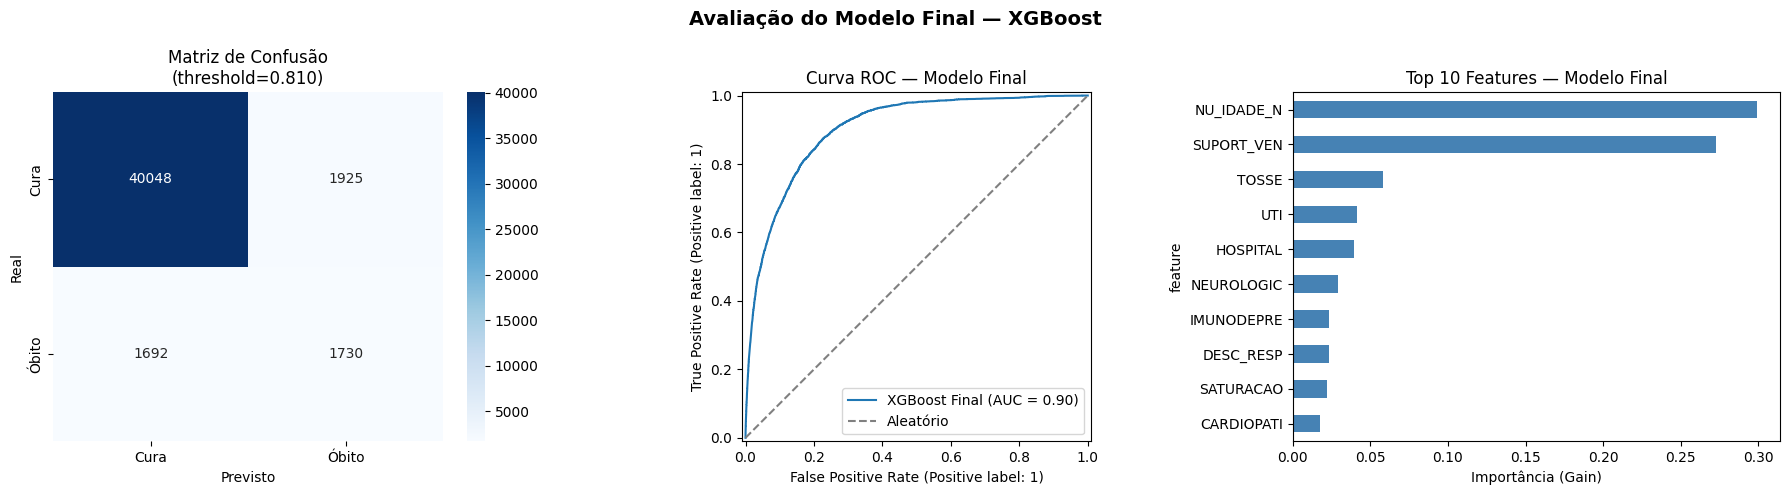

Verdadeiros Positivos (óbitos identificados): 1,730 (50.6%)
Falsos Negativos      (óbitos perdidos):      1,692 (49.4%)


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Matriz de confusão — threshold ótimo
cm = confusion_matrix(y_test_f, y_pred_test_f)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Cura', 'Óbito'], yticklabels=['Cura', 'Óbito'], ax=axes[0])
axes[0].set_title(f'Matriz de Confusão\n(threshold={best_thr_final:.3f})')
axes[0].set_ylabel('Real')
axes[0].set_xlabel('Previsto')

# Curva ROC — modelo final
RocCurveDisplay.from_predictions(y_test_f, y_prob_test_f, name='XGBoost Final', ax=axes[1])
axes[1].plot([0,1],[0,1],'--', color='gray', label='Aleatório')
axes[1].set_title('Curva ROC — Modelo Final')
axes[1].legend()

# Top features — modelo final
imp_final = pd.DataFrame({
    'feature': X_train_f.columns,
    'importancia': xgb_final.feature_importances_
}).sort_values('importancia', ascending=False).head(10)

imp_final.sort_values('importancia').plot(
    kind='barh', x='feature', y='importancia',
    color='steelblue', legend=False, ax=axes[2]
)
axes[2].set_title('Top 10 Features — Modelo Final')
axes[2].set_xlabel('Importância (Gain)')

plt.suptitle('Avaliação do Modelo Final — XGBoost', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

fn = cm[1][0]; tp = cm[1][1]
total_obitos = fn + tp
print(f"Verdadeiros Positivos (óbitos identificados): {tp:,} ({tp/total_obitos*100:.1f}%)")
print(f"Falsos Negativos      (óbitos perdidos):      {fn:,} ({fn/total_obitos*100:.1f}%)")


### 12.1 Curva Precision-Recall com Análise de Threshold

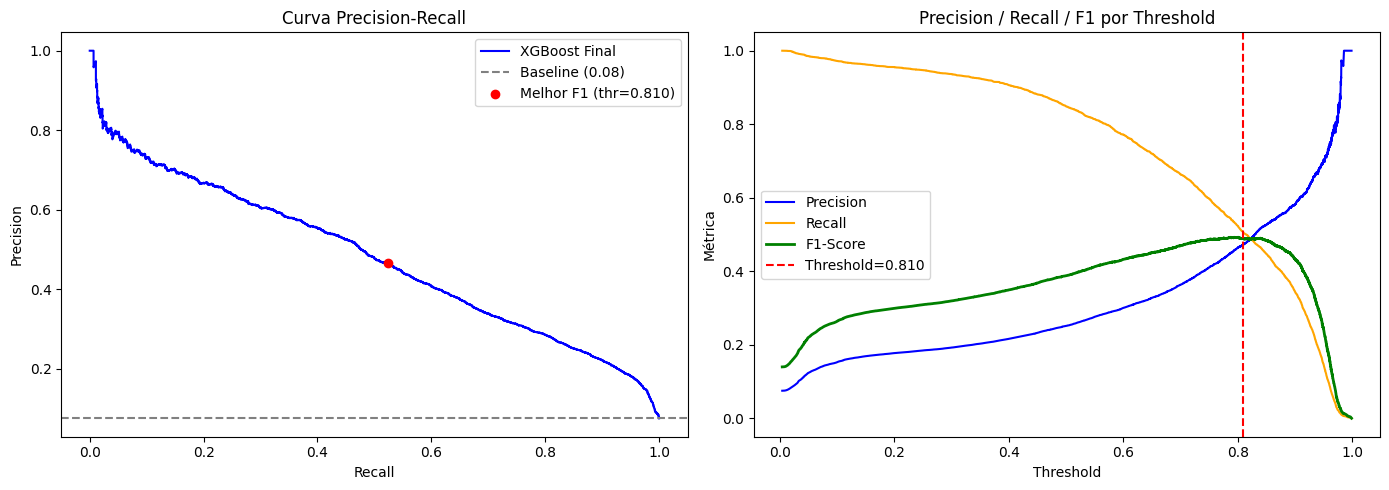

In [31]:
prec_test, rec_test, thr_test = precision_recall_curve(y_test_f, y_prob_test_f)
f1_test = 2 * prec_test * rec_test / (prec_test + rec_test + 1e-10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Curva PR
axes[0].plot(rec_test, prec_test, color='blue', label='XGBoost Final')
axes[0].axhline(y=y_test_f.mean(), color='gray', linestyle='--',
                label=f'Baseline ({y_test_f.mean():.2f})')
axes[0].scatter([rec_test[np.argmax(f1_test)]], [prec_test[np.argmax(f1_test)]],
                color='red', zorder=5, label=f'Melhor F1 (thr={best_thr_final:.3f})')
axes[0].set_xlabel('Recall'); axes[0].set_ylabel('Precision')
axes[0].set_title('Curva Precision-Recall'); axes[0].legend()

# F1 por threshold
axes[1].plot(thr_test, prec_test[:-1], label='Precision', color='blue')
axes[1].plot(thr_test, rec_test[:-1], label='Recall', color='orange')
axes[1].plot(thr_test, f1_test[:-1], label='F1-Score', color='green', linewidth=2)
axes[1].axvline(x=best_thr_final, color='red', linestyle='--',
                label=f'Threshold={best_thr_final:.3f}')
axes[1].set_xlabel('Threshold'); axes[1].set_ylabel('Métrica')
axes[1].set_title('Precision / Recall / F1 por Threshold'); axes[1].legend()

plt.tight_layout()
plt.show()

## 13. Análise de Complexidade Computacional

| Etapa | Complexidade | Observação |
|-------|-------------|------------|
| **Carregamento do dataset** | O(n × m) | n=335K registros, m=194 colunas |
| **EDA e fill rate** | O(n × m) | Varredura completa do dataset |
| **Remoção de outliers** | O(n) | Filtro linear por coluna |
| **Extração de texto (regex)** | O(n × L) | L = comprimento médio do texto |
| **Imputação por moda** | O(n × m') | m' = features selecionadas (~28) |
| **Train/test split** | O(n) | |
| **SMOTE** | O(k × n₁) | k=5 vizinhos; n₁ = amostras da classe minoritária |
| **SMOTEENN** | O(k × n) | Mais custoso — limpa bordas de decisão |
| **Árvore de Decisão** (treino) | O(n × m' × log n) | max_depth=4 limita a profundidade |
| **Regressão Logística** (treino) | O(n × m' × iter) | max_iter=5000 |
| **XGBoost** (treino) | O(n_est × n × m') | n_est=300 estimadores, early stopping não usado |
| **LightGBM** (treino) | O(n_est × n × log(bins)) | Histograma — mais eficiente que XGBoost em grandes bases |

**Conclusão sobre escalabilidade:**  
Com 302K registros e 28 features, todos os modelos treinaram em poucos minutos em ambiente Colab.  
LightGBM é o mais eficiente em datasets grandes por usar histogramas de features.  
SMOTEENN é o passo de balanceamento mais custoso (~O(n²) no pior caso com ENN).


## 14. Discussão das Decisões Tomadas

### 14.1 Escolha da Métrica Principal
- **Acurácia foi descartada**: com 92.5% de Cura, um modelo que sempre prevê "Cura" tem 92.5% de acurácia sem aprender nada.
- **Priorizamos Recall** (sensibilidade para óbito): preferimos falsos alarmes a deixar um paciente em risco sem atenção.
- **PR-AUC** foi usada para comparação de modelos — mais informativa que ROC-AUC em bases desbalanceadas.

### 14.2 Threshold Dinâmico
- O threshold padrão de 0.5 não é ideal aqui.
- Testamos dois thresholds: **ótimo pelo F1** (calculado na validação) e **0.5** (padrão, mais recall).
- Em contexto médico, **threshold 0.5 pode ser preferível** pois identifica mais óbitos ao custo de mais falsos positivos.

### 14.3 Balanceamento — Por que RUS se saiu melhor?
- O dataset tem 300K amostras. SMOTE gerou 447K amostras sintéticas — muito custo computacional por ganho marginal.
- RUS reduziu para 36K amostras balanceadas — treino muito mais rápido.
- XGBoost + RUS obteve o melhor ROC-AUC e recall entre as variações.
- A alternativa nativa do XGBoost (`scale_pos_weight`) também se mostrou eficaz sem precisar reamostrar.

### 14.4 Colunas de Comorbidades com Alto Missing
- CARDIOPATI, DIABETES, etc. tinham 65-70% de nulos.
- **Decisão**: imputar com a moda em vez de remover as colunas.
- **Justificativa**: em dados hospitalares, o preenchimento é frequentemente oportunístico — ausência pode indicar que a informação não foi coletada, não que o paciente não tem a condição.

### 14.5 Regressão Linear Descartada
- Testada como experimento — produziu valores negativos (-0.48) incompatíveis com probabilidade.
- Regressão Logística resolve isso forçando saída entre 0 e 1.

### 14.6 Split 70/15/15 vs. 80/20
- Os modelos baseline usaram 80/20 para maximizar dados de treino.
- O modelo final adotou 70/15/15 para ter um conjunto de validação independente para seleção de threshold — evitando data leakage.


## 15. Conclusões

### Resumo dos Resultados

| Modelo | ROC-AUC | PR-AUC | F1 (óbito) | Recall |
|--------|---------|--------|------------|--------|
| Árvore de Decisão | ~0.88 | ~0.38 | ~0.45 | ~0.39 |
| Regressão Logística | ~0.87 | ~0.35 | ~0.42 | ~0.51 |
| LightGBM | ~0.90 | ~0.47 | ~0.50 | ~0.53 |
| **XGBoost + RUS** | **~0.91** | **~0.48** | **~0.50** | **~0.57** |
| XGBoost + SMOTE | ~0.90 | ~0.46 | ~0.46 | ~0.55 |
| XGBoost + SMOTEENN | ~0.90 | ~0.46 | ~0.49 | ~0.53 |

### Principais Aprendizados

1. **O desbalanceamento é o principal desafio** — sem técnicas de balanceamento ou `class_weight`, os modelos ignoram a classe de óbito.
2. **Suporte Ventilatório e Idade** são as features mais importantes em todos os modelos — variáveis de gravidade clínica previsível.
3. **XGBoost com RUS** apresentou o melhor equilíbrio entre performance e custo computacional.
4. **Threshold customizado** é essencial neste domínio — o padrão de 0.5 não é apropriado.
5. A **extração de tabagismo/obesidade por regex** capturou poucos casos (<0.5%) — os campos de texto são preenchidos de forma inconsistente nos hospitais brasileiros.

### Limitações do Modelo

- O modelo não alcançou F1 ≥ 0.6 na classe de óbito — meta ambiciosa para um dataset clínico tão desafiador.
- Muitas features importantes (comorbidades) têm fill rate baixo (~35%), limitando o poder preditivo.
- O modelo não é diretamente aplicável em produção sem validação clínica externa.


#### Interpretação das Métricas

**ROC-AUC ≈ 0.91** indica boa capacidade discriminativa: em aproximadamente 91% dos pares aleatórios (um óbito real e uma cura real), o modelo atribui maior probabilidade ao óbito. Contudo, ROC-AUC é otimista em bases desbalanceadas — ela inclui regiões de threshold onde o modelo nunca operaria na prática.

**PR-AUC ≈ 0.48** é a métrica mais honesta aqui: um classificador aleatório teria PR-AUC ≈ 7.5% (prevalência da classe positiva). Atingir 0.48 representa uma melhora de ~6× sobre o baseline aleatório, mas ainda indica que a Precision ao identificar óbitos permanece limitada — reflexo direto do alto percentual de nulos nas comorbidades e da natureza heterogênea do dataset.

## 16. Possíveis Melhorias Futuras

1. **Multi-ano**: concatenar datasets de 2023-2025 para aumentar o volume e generalizar o modelo.
2. **Feature engineering**:
   - Tempo entre início dos sintomas e internação
   - Número total de comorbidades (variável agregada)
   - Faixa etária categórica
3. **XGBoost com NaN nativo**: em vez de imputar com moda, deixar o XGBoost tratar NaN internamente — provavelmente produziria melhores resultados nas features de comorbidades.
4. **Otimização de hiperparâmetros**: usar `Optuna` ou `GridSearchCV` para busca sistemática.
5. **Validação cruzada estratificada**: mais robusta que um único split treino/teste.
6. **Explicabilidade com SHAP**: visualizar contribuição individual de features por paciente.
7. **F-beta score com β > 1**: penalizar mais o falso negativo (óbito não identificado) durante a otimização de threshold.
8. **Análise temporal**: usar dados de 2019-2022 para treino e 2023-2025 para teste — simulação mais realista.
